# Statistical exploration of elliptic-curve cryptography 

## Population sampling method
Let the equation `E: y² = x³ -5x + 14  (mod p)`. \
Let `P = {7, 11, 19, 37, 61, 97}` as the p values set. The values are prime numbers between 4 and 100, approximately equally spaced on a logarithmic scale.

&forall; p in P: \
&emsp;&emsp;Get the valid curve E(p) points (Gs set), and &forall; the points: \
&emsp;&emsp;&emsp;&emsp;- Compute the subgroup order n. \
&emsp;&emsp;&emsp;&emsp;- Compute kG &forall; `k` &isin; `[2, 2n]`.

### Choices explanation
0. Equation parameters: no particular reason.
1. Multiple p values, logarithmic scale selection and subgroup order: to study the possible correlations between p, n and Gs dimension. 
2. kG computation for 2n-1 k values: to study the cyclic subgroups. Also linked to point no. 1.

## Data storage
The data is stored in a json file.

*hw1_data.json*:
one entry per coordinate with order, and list of `2n - 1` coordinated of kG


> {"p": {
>>     <index_i>: <Integer>
>>     ...
>  },
>  "G_o": {
>>     <index_i>: {
>>>        "x": <Integer>,
>>>        "y": <Integer>,
>>>        "n": <Integer>
>>     },
>>     ...
>  },
>  "kG": {
>>     <index_i>: [
>>>        {
>>>>           "x": <Integer>,
>>>>           "y": <Integer>
>>>        },
>>>        ...
>>     ]
>  }}

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

P = [7, 11, 19, 37, 61, 97]

data: pd.Dataframe = pd.read_json('hw1_data.json')
# Unfolding data
data[['Xg', 'Yg', 'n']] = data['G_o'].apply(pd.Series)
data.drop(columns=['G_o'], inplace=True)

## Descriptive analysis
The generated data is composed of 238 extracted curve points.

We can notice that some subgroup order values (`n`) are None. The only invalid data in the dataset. When n is None the list of kG is empty. The reason can be attributed to the "impossibility" of calculation in some cases. Impossibility intended as program crashes caused by the presence of vertical lines (or other factors), with the subsequent discard of all the good previous calculations.

A partial visualization of the dataset:

In [2]:
display(pd.concat([data.head(8), data.tail(8)]))

,p,kG,Xg,Yg,n
0,7,[],0.0,0.0,NaN
1,7,[],4.0,3.0,NaN
2,7,[],4.0,4.0,NaN
3,7,[],5.0,3.0,NaN
4,7,[],5.0,4.0,NaN
5,7,[],6.0,2.0,NaN
6,7,[],6.0,5.0,NaN
7,11,"[{'x': 3, 'y': 2}, {'x': 9, 'y': 4}, {'x': 5, ...",0.0,5.0,15.0
230,97,"[{'x': 42, 'y': 47}, {'x': 29, 'y': 28}, {'x':...",92.0,37.0,53.0
231,97,"[{'x': 42, 'y': 50}, {'x': 29, 'y': 69}, {'x':...",92.0,60.0,53.0


### Univariate analysis
Simple descriptive analysis of the single variables. For each step, will be displayed the result of all the p values.

Variables examined:
- subgroup order n
- distribution of x and y coordinate of G
- distribution of (x, y) coordinate of kG, with G that sup{card(G)}

*Note*: the distribution of (x, y) coordinate of G is not examined because is obvious. The G set has only unique points. \
*Note*: the reason of picking the particular G for kG, is to get the maximum number of points to work with. 

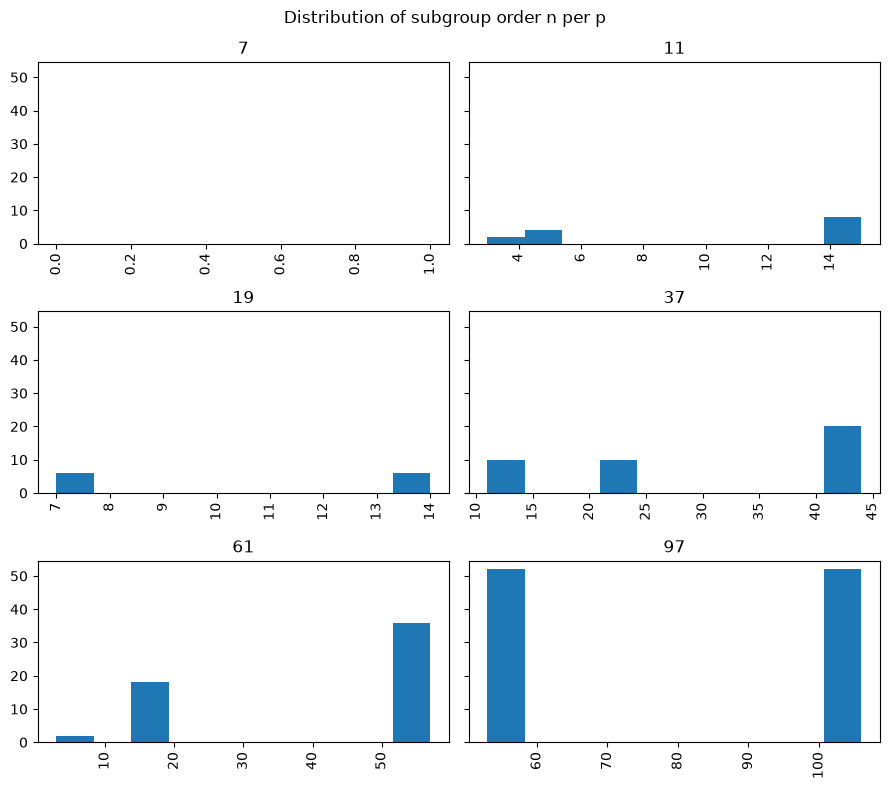

In [3]:
data.n.hist(by=data.p, sharey=True, figsize=(9, 8))
plt.suptitle("Distribution of subgroup order n per p")
plt.tight_layout()

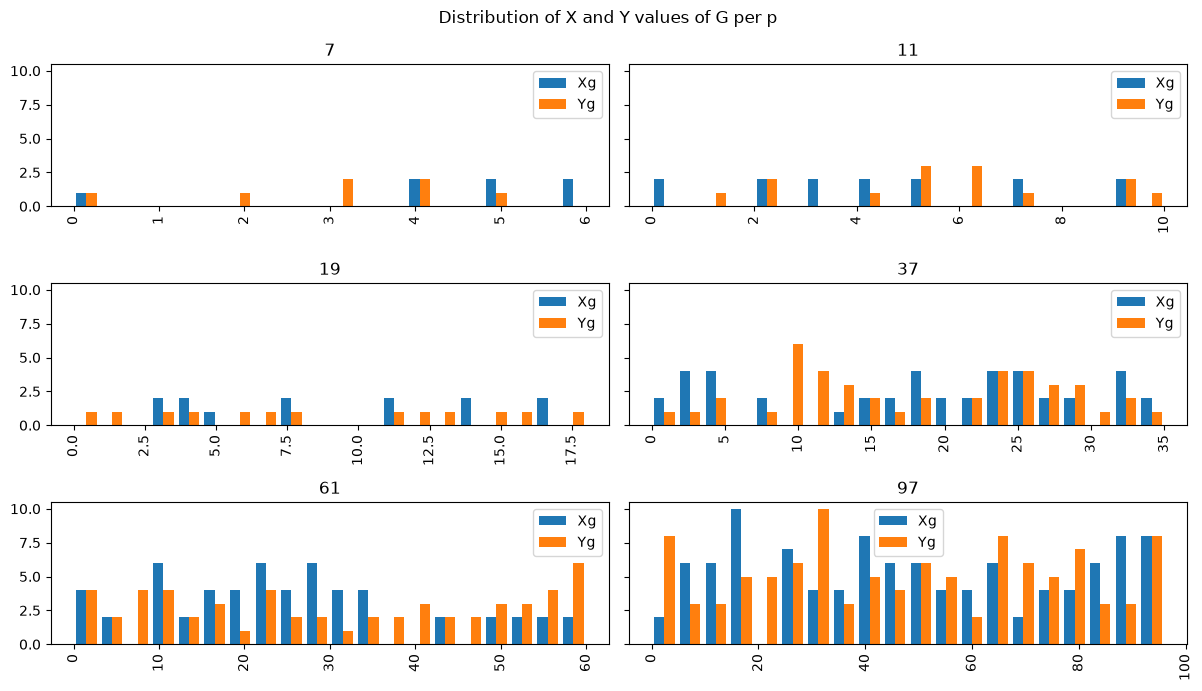

In [4]:
data.hist(column=['Xg', 'Yg'], by=data.p, sharey=True, bins=20, legend=True, figsize=(12, 7))
plt.suptitle("Distribution of X and Y values of G per p")
plt.tight_layout()

In [5]:
def find_G_which_sup_card_kG(p: int) -> dict(Xg, Yg):
    a = data[data.p == p].dropna()
    if a.empty:
        return {}
    return a.iloc[[a.kG.apply(len).argmax()]][['Xg', 'Yg']].to_dict(orient='records')[0]

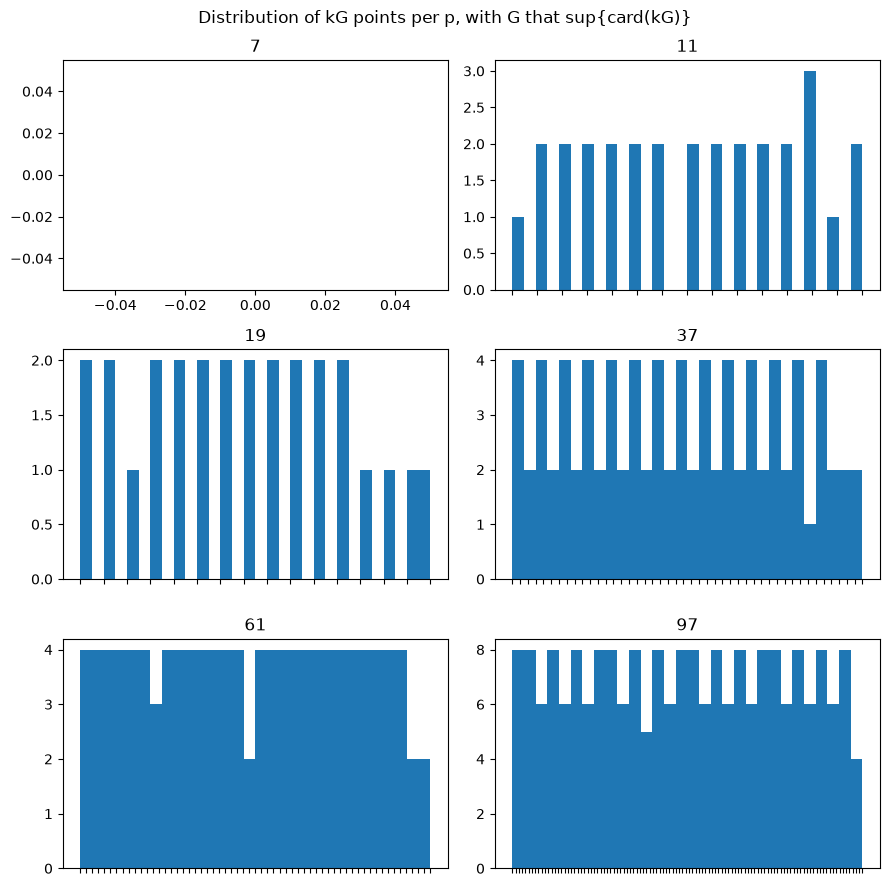

In [6]:
import json

fig, axs = plt.subplots(3, 2, figsize = (9, 9))

for ax, p in zip(axs.flatten(), P):
    sup = find_G_which_sup_card_kG(p)
    if sup != {}:
        temp = data[(data.p == p) & (data.Xg == sup['Xg']) & (data.Yg == sup['Yg'])].explode('kG', ignore_index=True)
        temp.kG = temp.kG.map(json.dumps)
        ax.hist(temp.kG, bins=30)
        ax.set(xticklabels=[])
    else:
        ax.scatter([], [])
    ax.set_title(p)

plt.suptitle("Distribution of kG points per p, with G that sup{card(kG)}")
plt.tight_layout()
plt.show()

This plot shows that there is repetition in kG points. That's because of the pigeonhole principle: kQ with k --> +Inf and only n finite points.

<!-- if you compute 2G jumping to G'. If you find G'' that 2G'' is G, 3G'' will be G'? If not, is always that or a particular case can make it happen? And if this case exists, what characteristics has? -->

---
### Bivariate analysis

Let's examine the x and y coordinates for G points.

In the following figure, the color of the dot is linked to the order of the subgroup generated from it. For small values of n the color is green. Higher the order, more blue becomes.

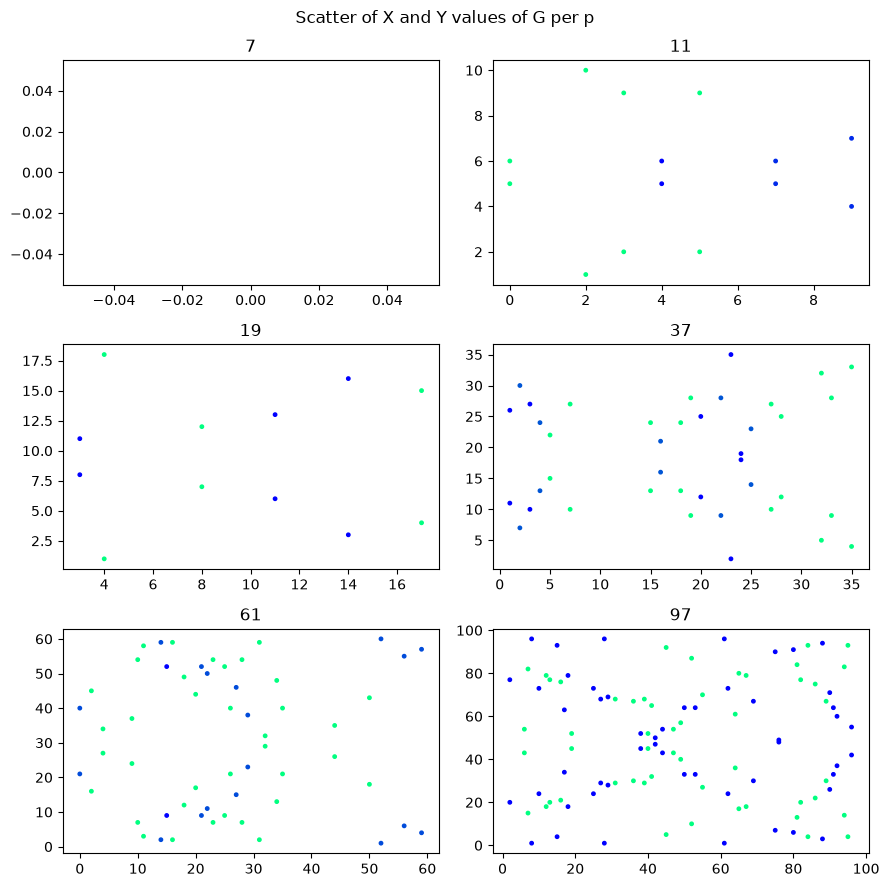

In [7]:
fig, axs = plt.subplots(3, 2, figsize = (9, 9))

for ax, p in zip(axs.flatten(), P):
    ax.scatter(data[data.p == p].Xg, data[data.p == p].Yg, c=data[data.p == p].n, cmap="winter", s=6)
    ax.set_title(p)

plt.suptitle("Scatter of X and Y values of G per p")
plt.tight_layout()
plt.show()

These scatter plots show the symmetry for `y = p/2` as a result of the symmetry of the equation.

Few points are missing to complete the symmetry (one per plot). Because the Point of Infinity is not considered here.

For a better and solid analysis, particular mathematical/statistical methods should be used.

### The curiosities for a future time

1. How p, number of curve points, subgroup order, G coordinates, percentage of subgroups that are cyclic are linked.
2. What about the application of graph theory to the kG? Some papers are available in this direction.
3. The sparse dots plotted in R², how they behave in a different world: coordinate system, plotting technique...
4. and much, much more!